# Dealing with Outliers

In statistics, an outlier is a data point that differs significantly from other observations.An outlier may be due to variability in the measurement or it may indicate experimental error; the latter are sometimes excluded from the data set. An outlier can cause serious problems in statistical analyses.

Remember that even if a data point is an outlier, its still a data point! Carefully consider your data, its sources, and your goals whenver deciding to remove an outlier. Each case is different!

## Lecture Goals
* Understand different mathmatical definitions of outliers
* Use Python tools to recognize outliers and remove them

### Useful Links

* [Wikipedia Article](https://en.wikipedia.org/wiki/Outlier)
* [NIST Outlier Links](https://www.itl.nist.gov/div898/handbook/prc/section1/prc16.htm)

-------------

# Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Generating Data

In [2]:
# Choose a mean,standard deviation, and number of samples

def create_ages(mu=50,sigma=13,num_samples=100,seed=42):

    # Set a random seed in the same cell as the random call to get the same values as us
    # We set seed to 42 (42 is an arbitrary choice from Hitchhiker's Guide to the Galaxy)
    np.random.seed(seed)

    sample_ages = np.random.normal(loc=mu,scale=sigma,size=num_samples)
    sample_ages = np.round(sample_ages,decimals=0)
    
    return sample_ages

In [3]:
sample = create_ages()

In [4]:
sample

array([56., 48., 58., 70., 47., 47., 71., 60., 44., 57., 44., 44., 53.,
       25., 28., 43., 37., 54., 38., 32., 69., 47., 51., 31., 43., 51.,
       35., 55., 42., 46., 42., 74., 50., 36., 61., 34., 53., 25., 33.,
       53., 60., 52., 48., 46., 31., 41., 44., 64., 54., 27., 54., 45.,
       41., 58., 63., 62., 39., 46., 54., 63., 44., 48., 36., 34., 61.,
       68., 49., 63., 55., 42., 55., 70., 50., 70., 16., 61., 51., 46.,
       51., 24., 47., 55., 69., 43., 39., 43., 62., 54., 43., 57., 51.,
       63., 41., 46., 45., 31., 54., 53., 50., 47.])

## Visualize and Describe the Data

C:\Users\fafzali\AppData\Local\Temp\ipykernel_20576\1469585388.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample,bins=10,kde=False)


<Axes: >

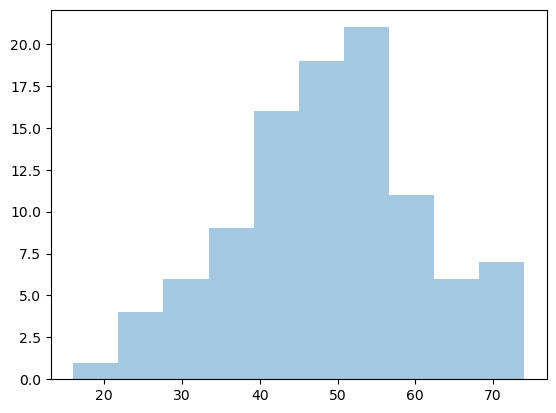

In [5]:
sns.distplot(sample,bins=10,kde=False)

<Axes: >

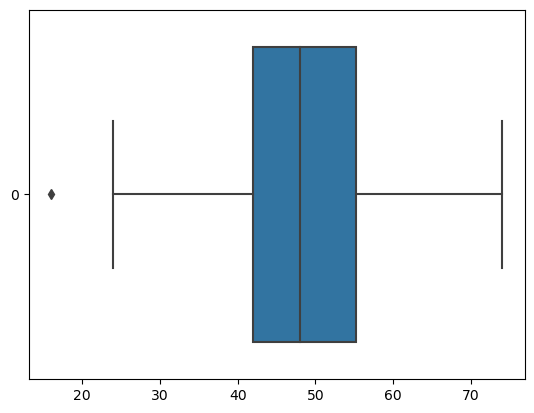

In [8]:
sns.boxplot(sample,orient ='h')

In [7]:
ser = pd.Series(sample)
ser.describe()

count    100.00000
mean      48.66000
std       11.82039
min       16.00000
25%       42.00000
50%       48.00000
75%       55.25000
max       74.00000
dtype: float64

In [12]:
np.percentile(sample,[0.75,0.5])

array([21.94, 19.96])

## Trimming or Fixing Based Off Domain Knowledge

If we know we're dealing with a dataset pertaining to voting age (18 years old in the USA), then it makes sense to either drop anything less than that OR fix values lower than 18 and push them up to 18.

In [8]:
ser[ser > 18]

0     56.0
1     48.0
2     58.0
3     70.0
4     47.0
      ... 
95    31.0
96    54.0
97    53.0
98    50.0
99    47.0
Length: 99, dtype: float64

In [12]:
# It dropped one person
len(ser[ser > 18])

99

In [9]:
def fix_values(age):
    
    if age < 18:
        return 18
    else:
        return age

In [10]:
# "Fixes" one person's age
ser.apply(fix_values)

0     56.0
1     48.0
2     58.0
3     70.0
4     47.0
      ... 
95    31.0
96    54.0
97    53.0
98    50.0
99    47.0
Length: 100, dtype: float64

In [11]:
len(ser.apply(fix_values))

100

--------

There are many ways to identify and remove outliers:
* Trimming based off a provided value
* Capping based off IQR or STD
* https://towardsdatascience.com/ways-to-detect-and-remove-the-outliers-404d16608dba
* https://towardsdatascience.com/5-ways-to-detect-outliers-that-every-data-scientist-should-know-python-code-70a54335a623

## Ames Data Set

Let's explore any extreme outliers in our Ames Housing Data Set

In [12]:
df = pd.read_csv(r"C:\Users\fafzali\Downloads\Machine learning\Code\Week 6\ames.csv")

In [13]:
df.head()

,Order,PID,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
0,1,526301100,1656,215000,20,RL,141.0,31770,Pave,NaN,...,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
1,2,526350040,896,105000,20,RH,80.0,11622,Pave,NaN,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
2,3,526351010,1329,172000,20,RL,81.0,14267,Pave,NaN,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
3,4,526353030,2110,244000,20,RL,93.0,11160,Pave,NaN,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
4,5,527105010,1629,189900,60,RL,74.0,13830,Pave,NaN,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal


C:\Users\fafzali\AppData\Local\Temp\ipykernel_20576\1547377726.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(df.corr())


<Axes: >

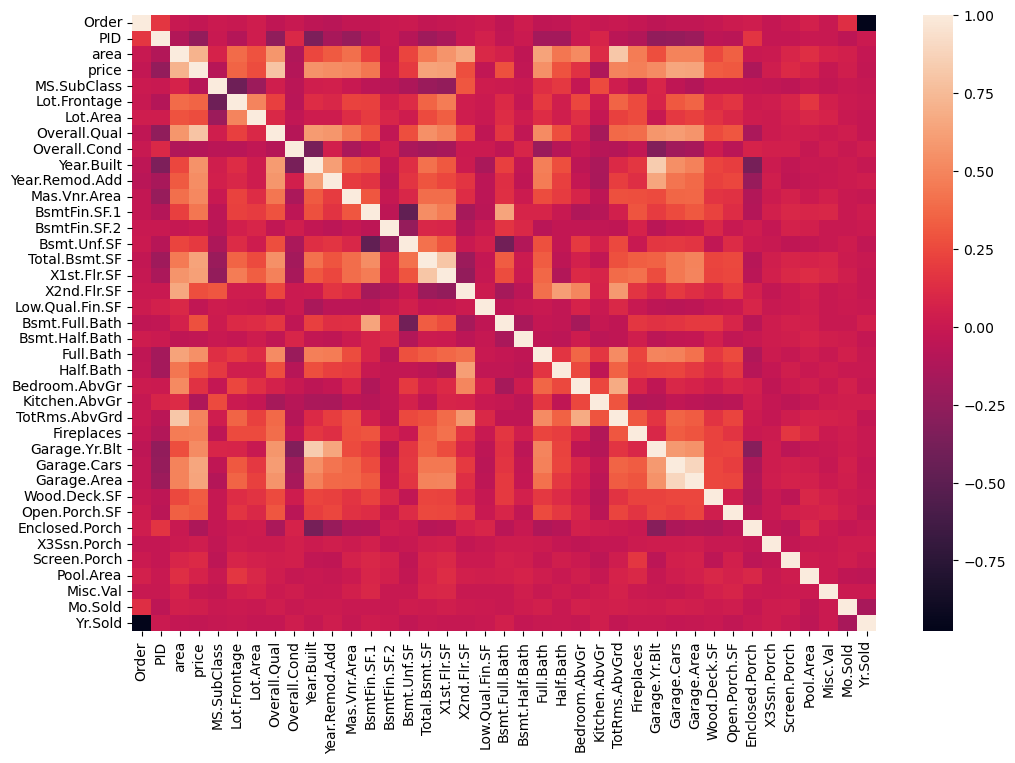

In [15]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr())

In [17]:
df.corr()['price'].sort_values()

C:\Users\fafzali\AppData\Local\Temp\ipykernel_20576\321850276.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()['price'].sort_values()


PID               -0.246521
Enclosed.Porch    -0.128787
Kitchen.AbvGr     -0.119814
Overall.Cond      -0.101697
MS.SubClass       -0.085092
Low.Qual.Fin.SF   -0.037660
Bsmt.Half.Bath    -0.035835
Order             -0.031408
Yr.Sold           -0.030569
Misc.Val          -0.015691
BsmtFin.SF.2       0.005891
X3Ssn.Porch        0.032225
Mo.Sold            0.035259
Pool.Area          0.068403
Screen.Porch       0.112151
Bedroom.AbvGr      0.143913
Bsmt.Unf.SF        0.182855
Lot.Area           0.266549
X2nd.Flr.SF        0.269373
Bsmt.Full.Bath     0.276050
Half.Bath          0.285056
Open.Porch.SF      0.312951
Wood.Deck.SF       0.327143
Lot.Frontage       0.357318
BsmtFin.SF.1       0.432914
Fireplaces         0.474558
TotRms.AbvGrd      0.495474
Mas.Vnr.Area       0.508285
Garage.Yr.Blt      0.526965
Year.Remod.Add     0.532974
Full.Bath          0.545604
Year.Built         0.558426
X1st.Flr.SF        0.621676
Total.Bsmt.SF      0.632280
Garage.Area        0.640401
Garage.Cars        0

C:\Users\fafzali\AppData\Local\Temp\ipykernel_20576\1956909199.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["price"],kde=False);


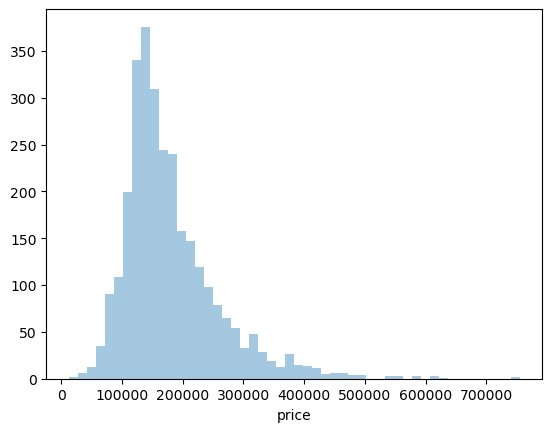

In [20]:
sns.distplot(df["price"],kde=False);

<Axes: xlabel='Overall.Qual', ylabel='price'>

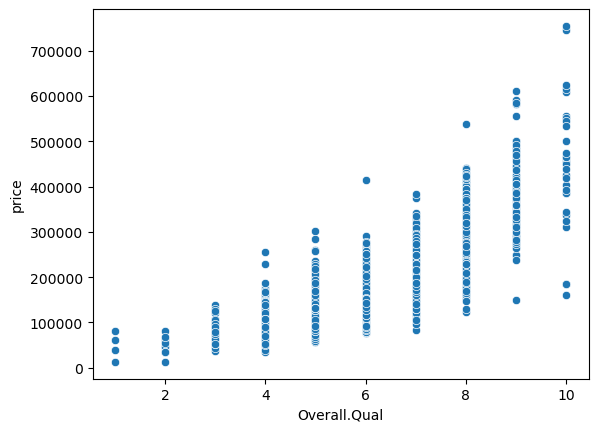

In [22]:
sns.scatterplot(x='Overall.Qual',y='price',data=df)

In [24]:
df[(df['Overall.Qual']>8) & (df['price']<200000)]

,Order,PID,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
1182,1183,533350090,2944,150000,60,RL,NaN,24572,Pave,NaN,...,0,0,NaN,NaN,NaN,0,6,2008,WD,Family
1498,1499,908154235,5642,160000,60,RL,313.0,63887,Pave,NaN,...,0,480,Gd,NaN,NaN,0,1,2008,New,Partial
2180,2181,908154195,5095,183850,20,RL,128.0,39290,Pave,NaN,...,0,0,NaN,NaN,Elev,17000,10,2007,New,Partial
2181,2182,908154205,4676,184750,60,RL,130.0,40094,Pave,NaN,...,0,0,NaN,NaN,NaN,0,10,2007,New,Partial


<Axes: xlabel='area', ylabel='price'>

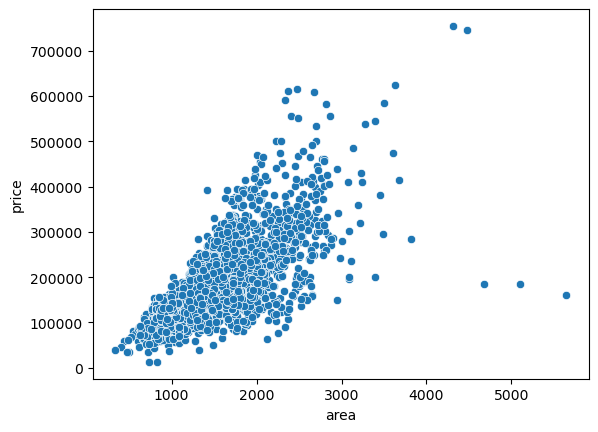

In [27]:
sns.scatterplot(x='area',y='price',data=df)

In [28]:
df[(df['area']>4000) & (df['price']<400000)]

,Order,PID,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
1498,1499,908154235,5642,160000,60,RL,313.0,63887,Pave,NaN,...,0,480,Gd,NaN,NaN,0,1,2008,New,Partial
2180,2181,908154195,5095,183850,20,RL,128.0,39290,Pave,NaN,...,0,0,NaN,NaN,Elev,17000,10,2007,New,Partial
2181,2182,908154205,4676,184750,60,RL,130.0,40094,Pave,NaN,...,0,0,NaN,NaN,NaN,0,10,2007,New,Partial


In [33]:
df[(df['area']>4000) & (df['price']<400000)].index

Int64Index([1498, 2180, 2181], dtype='int64')

In [29]:
ind_drop = df[(df['area']>4000) & (df['price']<400000)].index

In [30]:
df = df.drop(ind_drop,axis=0)

<Axes: xlabel='area', ylabel='price'>

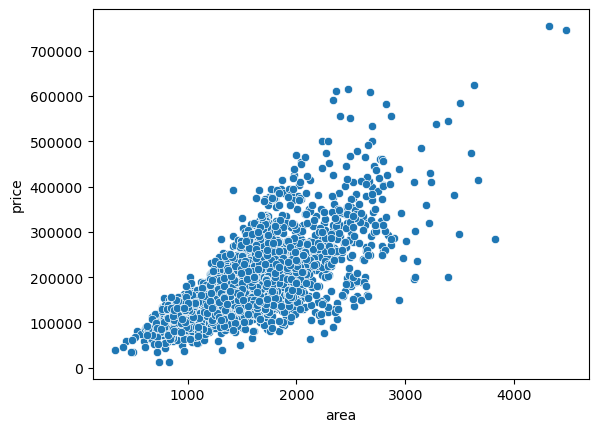

In [31]:
sns.scatterplot(x='area',y='price',data=df)

<Axes: xlabel='Overall.Qual', ylabel='price'>

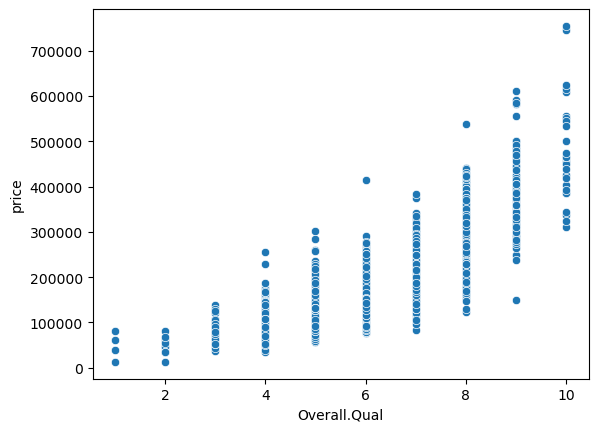

In [32]:
sns.scatterplot(x='Overall.Qual',y='price',data=df)

In [40]:
df.to_csv(r"C:\Users\fafzali\Downloads\Machine learning\Code\Week 6\ames_outlierremoved.csv", index=False)

----